# Logistic Regression
**Unit 4 · Lesson 4 | PV Time Series**  
Instructor: Sepehr Shakibi  
[Applied Machine Learning and Deep Learning for Photovoltaics with Python](https://github.com/SepehrShakibi/applied-ml-dl-for-photovoltaics-with-python)

Predict next-hour production **classes**, not continuous power, from measurements available at time t. Use the same prepared chronological partitions and feature set as Lessons 2–3. No repeated EDA or new cleaning is needed.

**Goals:** distinguish regression from classification; understand sigmoid and softmax; fit preprocessing only on train; compare explicit regularization settings; evaluate probabilities and labels; study binary decision thresholds; save the complete inference artifact.

The supplied PDF's cover says “Random Forest Classifier”, but its instructional content is Logistic Regression; this notebook follows that content.

## 1. Setup
Run from the project root. Download the prepared raw split CSVs, not scaled exports. If the downloaded folder layout differs, update `CONFIG["data_dir"]` below.

**Colab:** runtime storage is temporary. Download saved outputs or copy them to mounted Drive before the runtime ends. `gdown` does not mount Drive.

In [1]:
%pip install -q gdown
# %pip install -q numpy pandas matplotlib scikit-learn joblib

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    classification_report, ConfusionMatrixDisplay, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay,
)

In [3]:
!gdown --folder https://drive.google.com/drive/folders/1lFetK1YgncT5GPdLQFNrkuy8UWf-6881

Retrieving folder contents
Retrieving folder 14T5F5gwA0GGtPapainnN03f1IMhkXgec processed
Retrieving folder 1v372EjkxWn-8UdlhIvcPOS0ohwMXefZE pv_images
Processing file 1RFZRlUEIun3Z36gYpLClX8PRI4Og0Lql pv_images_test.csv
Processing file 1ZAqeFxVdPZu_uqfHT3Q7QRytm1CvbOnU pv_images_train.csv
Processing file 1pW98UOlS7Mh4LKHooN_1pzJjetJCnQFg pv_images_unknown.csv
Processing file 1hkMI_UN5FwmoSOfSXNuhz2zngOEjO-7k pv_images_validation.csv
Retrieving folder 1z994qLWlxE0mszwY1rLm8_1wQaso5gDB pv_time_series
Processing file 1DKNF0q9QHGBQSywBeNCC37bCEexxyWFq column_mapping.csv
Processing file 1bJlRxrYgcVEA1u383vq-F5g7E_lUQW3A pv_time_series_preprocessing.joblib
Processing file 1H5WyuYLz-Hye9SERAy1O3pu4grXmtLcJ pv_time_series_test_encoded.csv
Processing file 1ErXBDQHcCYa3aFv8rL0u7GTJkutuY5On pv_time_series_test_standardized.csv
Processing file 1IB0qv5K87J6MGmc8Q7SG-Q0lC745In1r pv_time_series_test.csv
Processing file 1nHbXSH4AxfpEwkwcqBfWOQVOI96SGaZQ pv_time_series_train_encoded.csv
Processing file

In [4]:
PROJECT_ROOT = os.path.abspath(".")
CONFIG = {
    "data_dir": os.path.join(PROJECT_ROOT, "data", "processed", "pv_time_series"),
    "output_dir": os.path.join(PROJECT_ROOT, "outputs", "04_04_logistic_regression"),
}

## 2. Load the existing partitions and labels
Retain the chronological 70/15/15 split. Next-hour targets were aligned within each partition in Unit 3. Unlike the generic random split on the slides, do not randomly shuffle this forecasting dataset.

Use the existing `target_class_t_plus_1` column directly. Its labels are **low, medium, high**, with zero included in low. Unit 3 defined the boundaries from the 1/3 and 2/3 quantiles of positive training targets only. These are teaching production categories, not fault labels or verified engineering limits.

Do not recreate labels or recompute boundaries on validation or test. This notebook needs only the three prepared CSVs; it does not load `preparation_metadata.json`. The exact physical boundaries remain part of the upstream dataset documentation, not something Logistic Regression learns.

In [5]:
train_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_train.csv"))
validation_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_validation.csv"))
test_data = pd.read_csv(os.path.join(CONFIG["data_dir"], "pv_time_series_test.csv"))

print("Train:", train_data.shape)
print("Validation:", validation_data.shape)
print("Test:", test_data.shape)
display(train_data.head())

Train: (4955, 25)
Validation: (1061, 25)
Test: (1061, 25)


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power,time_index,target_time_index,target_power_t_plus_1,target_class_t_plus_1
0,1,0.999852,1,1.0000,2,81,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,0,1,0.0,low
1,1,0.999852,2,0.9659,-1,86,0,900.2,10,0.0,...,0,0.0,0,0.0,0,0,1,2,0.0,low
2,1,0.999852,3,0.8660,0,87,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,2,3,0.0,low
3,1,0.999852,4,0.7071,-1,86,2,900.2,10,0.0,...,0,0.0,0,0.0,0,0,3,4,0.0,low
4,1,0.999852,5,0.5000,-1,86,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0,4,5,0.0,low


## 3. Separate inputs from labels
Keep the same numeric measurements and weather input as the previous lessons. Both future targets, raw time keys and target-alignment metadata are excluded from X. Current PV power is allowed for rolling one-hour-ahead forecasts because it is measured at prediction time. This is not a day-ahead forecast.

In [6]:
CLASS_NAMES = ["low", "medium", "high"]
TARGET = "target_class_t_plus_1"
NUMERIC_FEATURES = [
    "cosine_of_day", "cosine_of_hour", "air_temperature", "dewpoint",
    "wind_speed", "air_pressure", "solar_radiation",
    "pv_1_cosine_value_of_the_solar_incidence_angle", "pv_1_power",
    "pv_2_cosine_value_of_the_solar_incidence_angle", "pv_2_power",
    "pv_3_cosine_value_of_the_solar_incidence_angle", "pv_3_power",
    "pv_4_cosine_value_of_the_solar_incidence_angle", "pv_4_power",
    "pv_5_cosine_value_of_the_solar_incidence_angle", "pv_5_power",
]
CATEGORICAL_FEATURES = ["weather_condition"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train = train_data[FEATURES]
y_train = train_data[TARGET]
X_validation = validation_data[FEATURES]
y_validation = validation_data[TARGET]
X_test = test_data[FEATURES]
y_test = test_data[TARGET]

print("Number of inputs:", len(FEATURES))

Number of inputs: 18


In [7]:
display(pd.DataFrame({
    "train": y_train.value_counts(),
    "validation": y_validation.value_counts(),
}).reindex(CLASS_NAMES))
assert set(y_train.unique()) == set(CLASS_NAMES), "All three classes must be represented in train."
assert set(y_validation.unique()) <= set(CLASS_NAMES)
assert set(y_test.unique()) <= set(CLASS_NAMES)

,train,validation
target_class_t_plus_1,,
low,3429,676
medium,765,145
high,761,240


## 4. Linear score → probability → label
Linear regression predicts an unbounded numeric value and is evaluated with MAE/RMSE. Logistic regression predicts class probabilities and is evaluated with classification metrics.

For binary classification:
\[
z=b+\mathbf{w}^{T}\mathbf{x},\qquad P(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.
\]
Several inputs still produce one binary probability. The threshold (often 0.5) converts that probability to a label; it is not a PV-power class boundary.

For three classes, multinomial logistic regression uses one score per class and softmax:
\[
P(y=k\mid x)=\frac{e^{z_k}}{\sum_j e^{z_j}}.
\]
`predict` chooses the largest probability. Probabilities sum to one. Although the production labels have an order, ordinary multinomial logistic regression does not explicitly model that ordering.

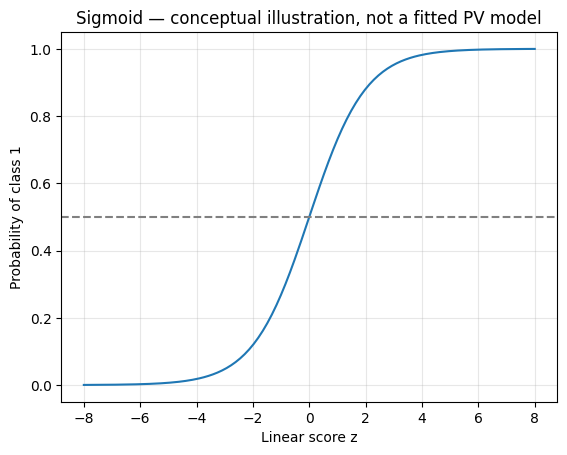

In [8]:
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))
plt.plot(z, sigmoid)
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Linear score z")
plt.ylabel("Probability of class 1")
plt.title("Sigmoid — conceptual illustration, not a fitted PV model")
plt.grid(alpha=0.3)
plt.show()

## 5. Explicit pipelines and regularization
As in Lesson 2, encode weather with `OrdinalEncoder` and standardize inputs inside each pipeline. Unknown weather maps to -1. Ordinal encoding imposes artificial category order and distance; one-hot encoding is a worthwhile separate experiment, not a silent change here.

All encoders, scalers and classifiers fit only on train. No target scaling is used. `lbfgs` fits a multinomial model when there are three classes. The default L2 regularization shrinks coefficients: **smaller C means stronger regularization**. Compare C=0.1, 1 and 10 explicitly, without loops or automatic selection.

`max_iter` is a solver iteration limit, not a learning rate. Do not suppress convergence warnings; if one occurs, inspect scaling and increase the limit before interpreting the fit.

The names `strong_pipeline` and `weak_pipeline` describe the strength of regularization, not model quality. Their only experimental difference is C; they use the same inputs, preprocessing and solver.

In [9]:
strong_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", "passthrough", NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=0.1, solver="lbfgs", max_iter=3000)),
])
strong_pipeline.fit(X_train, y_train)
print("Solver iterations:", strong_pipeline.named_steps["classifier"].n_iter_)

Solver iterations: [49]


In [10]:
standard_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", "passthrough", NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000)),
])
standard_pipeline.fit(X_train, y_train)
print("Solver iterations:", standard_pipeline.named_steps["classifier"].n_iter_)

Solver iterations: [95]


In [11]:
weak_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("numeric", "passthrough", NUMERIC_FEATURES),
        ("weather", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL_FEATURES),
    ])),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=10.0, solver="lbfgs", max_iter=3000)),
])
weak_pipeline.fit(X_train, y_train)
print("Solver iterations:", weak_pipeline.named_steps["classifier"].n_iter_)

Solver iterations: [134]


## 6. Evaluate Logistic Regression on validation
Evaluate each regularization setting separately. Accuracy can hide minority-class failures. Macro-F1 gives each class equal weight; use it as the primary comparison here, alongside per-class recall and probability log loss (lower is better). `zero_division=0` reports zero for undefined precision/recall rather than hiding an absent prediction.

This lesson deliberately focuses on Logistic Regression and omits baselines. Comparing these three settings identifies differences within this model family; it does not establish an advantage over simple forecasting rules.

In [12]:
strong_validation_prediction = strong_pipeline.predict(X_validation)
strong_validation_probability = strong_pipeline.predict_proba(X_validation)
strong_f1 = f1_score(y_validation, strong_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
strong_train_f1 = f1_score(y_train, strong_pipeline.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
print("Train macro-F1:", strong_train_f1)
print("Validation macro-F1:", strong_f1)
print("Validation accuracy:", accuracy_score(y_validation, strong_validation_prediction))
print("Validation log loss:", log_loss(y_validation, strong_validation_probability, labels=strong_pipeline.classes_))
print(classification_report(y_validation, strong_validation_prediction, labels=CLASS_NAMES, zero_division=0))

Train macro-F1: 0.8226225926018182
Validation macro-F1: 0.8781158006250257
Validation accuracy: 0.9302544769085768
Validation log loss: 0.17843878701531107
              precision    recall  f1-score   support

         low       0.97      0.98      0.97       676
      medium       0.75      0.73      0.74       145
        high       0.92      0.92      0.92       240

    accuracy                           0.93      1061
   macro avg       0.88      0.88      0.88      1061
weighted avg       0.93      0.93      0.93      1061



In [13]:
standard_validation_prediction = standard_pipeline.predict(X_validation)
standard_validation_probability = standard_pipeline.predict_proba(X_validation)
standard_f1 = f1_score(y_validation, standard_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
standard_train_f1 = f1_score(y_train, standard_pipeline.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
print("Train macro-F1:", standard_train_f1)
print("Validation macro-F1:", standard_f1)
print("Validation accuracy:", accuracy_score(y_validation, standard_validation_prediction))
print("Validation log loss:", log_loss(y_validation, standard_validation_probability, labels=standard_pipeline.classes_))
print(classification_report(y_validation, standard_validation_prediction, labels=CLASS_NAMES, zero_division=0))

Train macro-F1: 0.8250945294381623
Validation macro-F1: 0.8830242685607983
Validation accuracy: 0.9321394910461829
Validation log loss: 0.16419012624568582
              precision    recall  f1-score   support

         low       0.98      0.97      0.97       676
      medium       0.75      0.76      0.75       145
        high       0.92      0.92      0.92       240

    accuracy                           0.93      1061
   macro avg       0.88      0.88      0.88      1061
weighted avg       0.93      0.93      0.93      1061



In [14]:
weak_validation_prediction = weak_pipeline.predict(X_validation)
weak_validation_probability = weak_pipeline.predict_proba(X_validation)
weak_f1 = f1_score(y_validation, weak_validation_prediction, labels=CLASS_NAMES, average="macro", zero_division=0)
weak_train_f1 = f1_score(y_train, weak_pipeline.predict(X_train), labels=CLASS_NAMES, average="macro", zero_division=0)
print("Train macro-F1:", weak_train_f1)
print("Validation macro-F1:", weak_f1)
print("Validation accuracy:", accuracy_score(y_validation, weak_validation_prediction))
print("Validation log loss:", log_loss(y_validation, weak_validation_probability, labels=weak_pipeline.classes_))
print(classification_report(y_validation, weak_validation_prediction, labels=CLASS_NAMES, zero_division=0))

Train macro-F1: 0.8283622870820867
Validation macro-F1: 0.88090507721177
Validation accuracy: 0.9302544769085768
Validation log loss: 0.16059831181467815
              precision    recall  f1-score   support

         low       0.98      0.97      0.97       676
      medium       0.74      0.76      0.75       145
        high       0.92      0.93      0.92       240

    accuracy                           0.93      1061
   macro avg       0.88      0.88      0.88      1061
weighted avg       0.93      0.93      0.93      1061



In [15]:
display(pd.DataFrame({
    "regularization": ["Strong: C=0.1", "Default: C=1", "Weak: C=10"],
    "validation_macro_f1": [strong_f1, standard_f1, weak_f1],
    "train_macro_f1": [strong_train_f1, standard_train_f1, weak_train_f1],
}))

,regularization,validation_macro_f1,train_macro_f1
0,Strong: C=0.1,0.878116,0.822623
1,Default: C=1,0.883024,0.825095
2,Weak: C=10,0.880905,0.828362


### Manual choice
Compare validation macro-F1, per-class errors, and train–validation gaps. A gap can indicate overfitting or temporal distribution shift. Prefer stronger regularization when validation results are similar. C=1 below is only a teaching default, not an observed winner. Record your reasoning before proceeding; do not use test to revise the choice.

In [16]:
chosen_pipeline = standard_pipeline
selection_reason = "Teaching default C=1; replace with validation-based justification."
print(selection_reason)

Teaching default C=1; replace with validation-based justification.


## 7. Inspect probabilities, errors and coefficients
Probability columns follow `classes_`, **not** the low/medium/high display order. Use those names explicitly. Coefficients operate on standardized inputs and are not causal effects. In the multinomial model, differences between class coefficients determine log probability ratios; an individual coefficient is not a binary log-odds effect.

,high,low,medium
0,0.960541,0.000016,0.039443
1,0.739619,0.001057,0.259323
2,0.415121,0.005348,0.579531
3,0.081001,0.052721,0.866278
4,0.004394,0.371585,0.624021


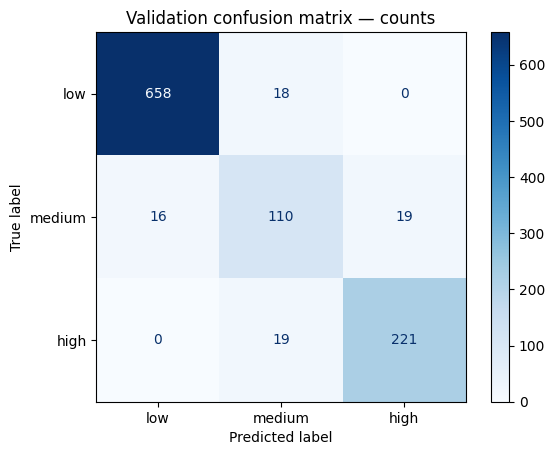

,day,hour,target_power_t_plus_1,target_class_t_plus_1,predicted_class
19,208,8,364.0,medium,low
21,208,10,782.0,medium,high
28,208,17,346.0,low,medium
68,210,9,894.0,high,medium
74,210,15,842.0,medium,high
76,210,17,304.0,low,medium
92,211,9,894.0,high,medium
98,211,15,845.0,medium,high
100,211,17,300.0,low,medium
116,212,9,875.0,high,medium


In [17]:
chosen_validation_prediction = chosen_pipeline.predict(X_validation)
chosen_validation_probability = chosen_pipeline.predict_proba(X_validation)
probability_table = pd.DataFrame(chosen_validation_probability, columns=chosen_pipeline.classes_, index=X_validation.index)
display(probability_table.head())
np.testing.assert_allclose(probability_table.sum(axis=1), 1.0)
ConfusionMatrixDisplay.from_predictions(y_validation, chosen_validation_prediction, labels=CLASS_NAMES, cmap="Blues")
plt.title("Validation confusion matrix — counts")
plt.show()
validation_errors = validation_data[["day", "hour", "target_power_t_plus_1", TARGET]].copy()
validation_errors["predicted_class"] = chosen_validation_prediction
display(validation_errors.loc[y_validation != chosen_validation_prediction].head(15))

,high,low,medium
numeric__cosine_of_day,-0.673572,1.128921,-0.455350
numeric__cosine_of_hour,-0.013679,2.542670,-2.528990
numeric__air_temperature,-0.569494,0.595683,-0.026189
numeric__dewpoint,0.249000,-0.287840,0.038839
numeric__wind_speed,-0.029332,0.094417,-0.065085
numeric__air_pressure,0.109077,-0.090513,-0.018564
numeric__solar_radiation,0.717465,-0.940116,0.222650
numeric__pv_1_cosine_value_of_the_solar_incidence_angle,0.132743,1.161832,-1.294576
numeric__pv_1_power,-0.599699,0.120041,0.479658
numeric__pv_2_cosine_value_of_the_solar_incidence_angle,0.602976,0.304843,-0.907819


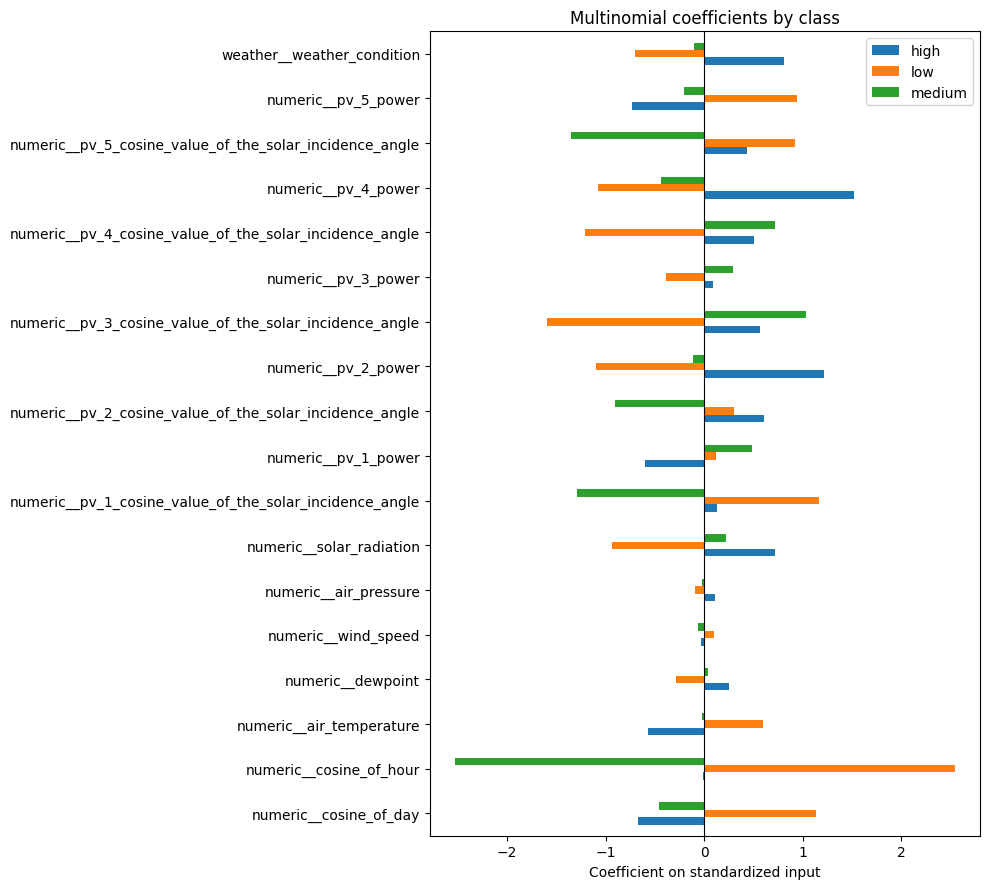

In [18]:
coefficient_table = pd.DataFrame(
    chosen_pipeline.named_steps["classifier"].coef_.T,
    index=chosen_pipeline.named_steps["features"].get_feature_names_out(),
    columns=chosen_pipeline.classes_,
)
display(coefficient_table)
coefficient_table.plot.barh(figsize=(10, 9))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient on standardized input")
plt.title("Multinomial coefficients by class")
plt.tight_layout()
plt.show()

## 8. Binary extension: high production versus the rest
To connect sigmoid and thresholding directly to the slides, fit a **separate binary logistic model** with the same chosen C. This is not a fault detector. Class 1 means next-hour power exceeds the fixed upper training boundary. We are not changing the label definition when changing a probability threshold.

Reuse the chosen preprocessing specification via `clone`; it is refitted on train only. Compare thresholds 0.3, 0.5 and 0.7 on validation. Lowering a threshold cannot reduce recall for fixed probabilities, but precision need not change monotonically. Choose based on the costs of false alarms and missed high-production events, not test results.

In [19]:
from sklearn.base import clone
binary_pipeline = clone(chosen_pipeline)
y_train_high = (y_train == "high").astype(int)
y_validation_high = (y_validation == "high").astype(int)
binary_pipeline.fit(X_train, y_train_high)
high_column = list(binary_pipeline.classes_).index(1)
high_validation_probability = binary_pipeline.predict_proba(X_validation)[:, high_column]

In [20]:
high_prediction_03 = (high_validation_probability >= 0.3).astype(int)
print("Threshold 0.3")
print("Precision:", precision_score(y_validation_high, high_prediction_03, zero_division=0))
print("Recall:", recall_score(y_validation_high, high_prediction_03, zero_division=0))
print("F1:", f1_score(y_validation_high, high_prediction_03, zero_division=0))

Threshold 0.3
Precision: 0.8550185873605948
Recall: 0.9583333333333334
F1: 0.9037328094302554


In [21]:
high_prediction_05 = (high_validation_probability >= 0.5).astype(int)
print("Threshold 0.5")
print("Precision:", precision_score(y_validation_high, high_prediction_05, zero_division=0))
print("Recall:", recall_score(y_validation_high, high_prediction_05, zero_division=0))
print("F1:", f1_score(y_validation_high, high_prediction_05, zero_division=0))

Threshold 0.5
Precision: 0.9205020920502092
Recall: 0.9166666666666666
F1: 0.918580375782881


In [22]:
high_prediction_07 = (high_validation_probability >= 0.7).astype(int)
print("Threshold 0.7")
print("Precision:", precision_score(y_validation_high, high_prediction_07, zero_division=0))
print("Recall:", recall_score(y_validation_high, high_prediction_07, zero_division=0))
print("F1:", f1_score(y_validation_high, high_prediction_07, zero_division=0))

Threshold 0.7
Precision: 0.9857142857142858
Recall: 0.8625
F1: 0.92


ROC-AUC measures probability ranking, not thresholded-label accuracy. Precision–recall curves help assess positive-class retrieval. Both need positive and negative examples for meaningful interpretation. Neither a high AUC nor `predict_proba` guarantees calibrated probabilities.

Validation binary ROC-AUC: 0.9944884287454323


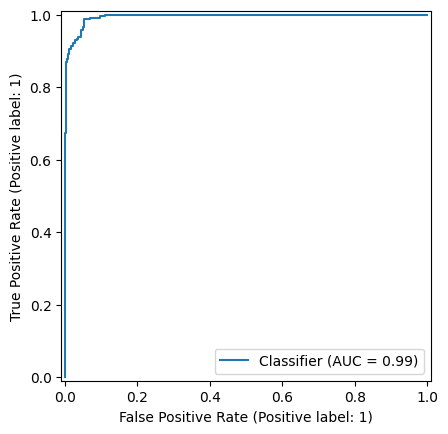

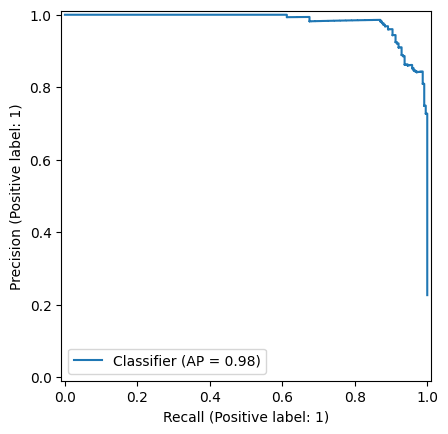

In [23]:
if y_validation_high.nunique() == 2:
    print("Validation binary ROC-AUC:", roc_auc_score(y_validation_high, high_validation_probability))
    RocCurveDisplay.from_predictions(y_validation_high, high_validation_probability)
    plt.show()
    PrecisionRecallDisplay.from_predictions(y_validation_high, high_validation_probability)
    plt.show()
else:
    print("Validation contains only one binary class; skip ranking curves and ROC-AUC.")

In [24]:
chosen_probability_threshold = 0.5
threshold_reason = "Teaching default 0.5; replace with validation/error-cost justification."
print(threshold_reason)

Teaching default 0.5; replace with validation/error-cost justification.


## 9. Final test — fixed decisions only
Run this section only after freezing C, the probability threshold and the reasons above. Report test performance once; do not return to tuning based on it. Keep train-fitted pipelines unchanged (no train+validation refit). The binary extension and multiclass task are different tasks, so their F1 scores are not competing model-selection scores.

Multiclass test accuracy: 0.9114043355325165
Multiclass test macro-F1: 0.8281229066287854
Multiclass test log loss: 0.2144148449152075
              precision    recall  f1-score   support

         low       0.98      0.95      0.96       740
      medium       0.59      0.64      0.61       117
        high       0.88      0.94      0.91       204

    accuracy                           0.91      1061
   macro avg       0.82      0.84      0.83      1061
weighted avg       0.92      0.91      0.91      1061



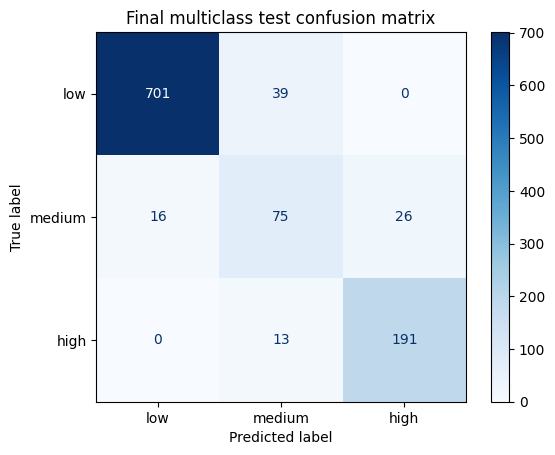

In [25]:
test_prediction = chosen_pipeline.predict(X_test)
test_probability = chosen_pipeline.predict_proba(X_test)
print("Multiclass test accuracy:", accuracy_score(y_test, test_prediction))
print("Multiclass test macro-F1:", f1_score(y_test, test_prediction, labels=CLASS_NAMES, average="macro", zero_division=0))
print("Multiclass test log loss:", log_loss(y_test, test_probability, labels=chosen_pipeline.classes_))
print(classification_report(y_test, test_prediction, labels=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=CLASS_NAMES, cmap="Blues")
plt.title("Final multiclass test confusion matrix")
plt.show()

In [26]:
y_test_high = (y_test == "high").astype(int)
high_test_probability = binary_pipeline.predict_proba(X_test)[:, high_column]
high_test_prediction = (high_test_probability >= chosen_probability_threshold).astype(int)
print(classification_report(y_test_high, high_test_prediction, labels=[0, 1], target_names=["not high", "high"], zero_division=0))
if y_test_high.nunique() == 2:
    print("Binary test ROC-AUC:", roc_auc_score(y_test_high, high_test_probability))
else:
    print("Binary test ROC-AUC is undefined: only one class is present.")

              precision    recall  f1-score   support

    not high       0.98      0.97      0.98       857
        high       0.88      0.92      0.90       204

    accuracy                           0.96      1061
   macro avg       0.93      0.95      0.94      1061
weighted avg       0.96      0.96      0.96      1061

Binary test ROC-AUC: 0.9901388793557095


## 10. Save and reload the complete artifact
Store both pipelines, the exact input schema, class names and the chosen binary probability threshold. No class boundaries are recomputed here: the model uses the labels already prepared in Unit 3. For deployment, keep the upstream label-definition documentation alongside this artifact if the exact production ranges are needed.

The saved probability threshold controls the binary high/rest decision; it is not a physical power boundary. Save predictions separately without overwriting any source CSV.

Only load trusted joblib files: deserialization can execute code. Record package versions because artifacts may not be portable across versions.

In [27]:
os.makedirs(CONFIG["output_dir"], exist_ok=True)
artifact = {
    "multiclass_pipeline": chosen_pipeline,
    "binary_pipeline": binary_pipeline,
    "features": FEATURES,
    "target": TARGET,
    "class_names": CLASS_NAMES,
    "label_source": "Existing target_class_t_plus_1 labels from Unit 3; train-derived boundaries",
    "probability_threshold": chosen_probability_threshold,
    "selection_reason": selection_reason,
    "threshold_reason": threshold_reason,
    "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
artifact_path = os.path.join(CONFIG["output_dir"], "logistic_regression_artifact.joblib")
joblib.dump(artifact, artifact_path)
test_output = test_data[["day", "hour", TARGET]].copy()
test_output["predicted_class"] = test_prediction
test_output["binary_high_probability"] = high_test_probability
test_output["binary_high_prediction"] = high_test_prediction
test_output.to_csv(os.path.join(CONFIG["output_dir"], "test_predictions.csv"), index=False)
print("Saved to:", CONFIG["output_dir"])

Saved to: /content/outputs/04_04_logistic_regression


In [28]:
loaded_artifact = joblib.load(artifact_path)
new_measurements = X_test.head(5)[loaded_artifact["features"]]
reloaded_labels = loaded_artifact["multiclass_pipeline"].predict(new_measurements)
np.testing.assert_array_equal(reloaded_labels, test_prediction[:5])
loaded_binary = loaded_artifact["binary_pipeline"]
loaded_high_column = list(loaded_binary.classes_).index(1)
reloaded_high_probability = loaded_binary.predict_proba(new_measurements)[:, loaded_high_column]
np.testing.assert_allclose(reloaded_high_probability, high_test_probability[:5])
reloaded_high_labels = (reloaded_high_probability >= loaded_artifact["probability_threshold"]).astype(int)
np.testing.assert_array_equal(reloaded_high_labels, high_test_prediction[:5])
print("Reload checks passed.")

Reload checks passed.


## Summary and exercises
- Logistic regression predicts probabilities and classes, not continuous PV output.
- Multinomial softmax handles three production classes; sigmoid handles the binary high/rest task.
- Train-only preprocessing and existing train-derived class boundaries prevent leakage.
- Compare regularization and probability thresholds on validation, then freeze them before test.
- Accuracy alone is insufficient: inspect macro-F1, class recall, confusion matrices and probability quality.

**Discuss:** Which classes are confused? Does stronger regularization reduce the train–validation gap? What operational cost would justify lowering the high-production probability threshold? Why are these production labels not evidence of panel damage?

**Execution note:** notebook structure and Python syntax are checked during preparation, and the workflow is smoke-tested on synthetic data. No results on the original PV CSVs are claimed.